In [1]:
import matplotlib.pyplot as plt
import seaborn as sns

import numpy as np
from scipy.stats import probplot, bootstrap
import jax
from jax import vmap
import jax.numpy as jnp
from jax.scipy.stats import norm

from embeddings import KTE
from utils import Array
from KRR_utils import learn_hyperparams
from DGPs import DGP_binary, DGP_univariate, DGP_multimodal, DGP_null, DGP_null_U

%matplotlib inline

(10000, 1)
(10000, 1)
(10000, 1)
(10000, 1)


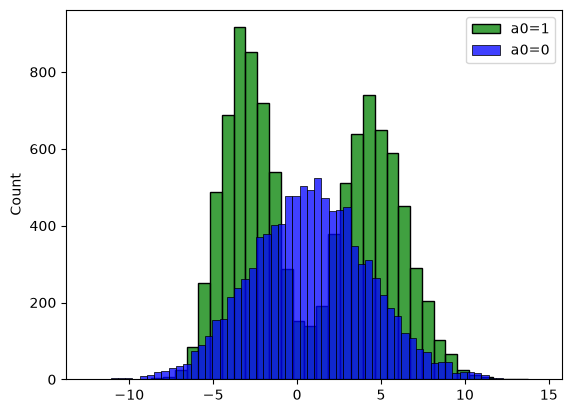

In [2]:
A_1,M_1,X_1,Y_1=DGP_multimodal(10000,seed=0,gt=True,a0=1)
A_0,M_0,X_0,Y_0=DGP_multimodal(10000,seed=1,gt=True,a0=0)
print(A_1.shape)
print(M_1.shape)
print(X_1.shape)
print(Y_1.shape)
sns.histplot(Y_1.ravel(),color="green",label="a0=1")
sns.histplot(Y_0.ravel(),color="blue",label="a0=0")
plt.legend()
plt.show()

(10000, 1)
(10000, 1)
(10000, 1)
(10000, 1)


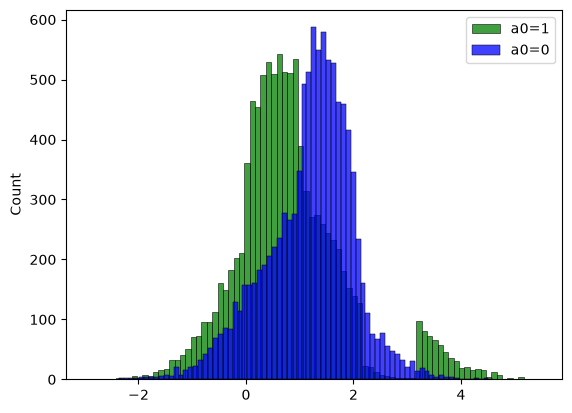

0.49049997
0.5002
0.5032


In [2]:
A_1,M_1,X_1,Y_1=DGP_binary(10000,seed=0,gt=True,a0=1)
A_0,M_0,X_0,Y_0=DGP_binary(10000,seed=1,gt=True,a0=0)
print(A_1.shape)
print(M_1.shape)
print(X_1.shape)
print(Y_1.shape)
sns.histplot(Y_1.ravel(),color="green",label="a0=1")
sns.histplot(Y_0.ravel(),color="blue",label="a0=0")
plt.legend()
plt.show()

A,M,X,Y=DGP_binary(10000,seed=0,gt=False,a0=1)
print(A.mean())
print(X.mean())
print(M.mean())

(10000, 1)
(10000, 1)
(10000, 1)
(10000, 1)


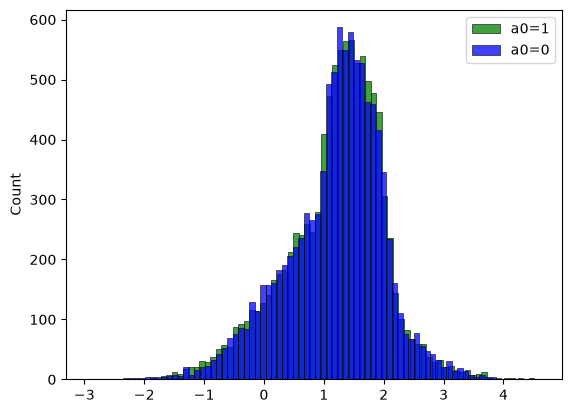

0.49049997
0.5002
0.6863


In [3]:
A_1,M_1,X_1,Y_1=DGP_binary(10000,seed=0,gt=True,a0=1,null=True)
A_0,M_0,X_0,Y_0=DGP_binary(10000,seed=1,gt=True,a0=0,null=True)
print(A_1.shape)
print(M_1.shape)
print(X_1.shape)
print(Y_1.shape)
sns.histplot(Y_1.ravel(),color="green",label="a0=1")
sns.histplot(Y_0.ravel(),color="blue",label="a0=0")
plt.legend()
plt.show()

A,M,X,Y=DGP_binary(10000,seed=0,gt=False,a0=1,null=True)
print(A.mean())
print(X.mean())
print(M.mean())

(10000, 1)
(10000, 1)
(10000, 1)
(10000, 1)


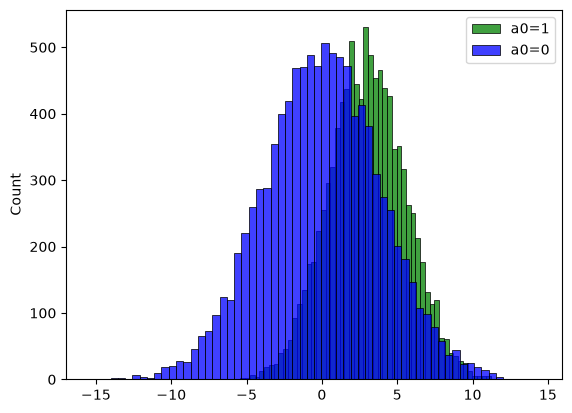

In [3]:
A_1,M_1,X_1,Y_1=DGP_univariate(10000,seed=0,gt=True,a0=1)
A_0,M_0,X_0,Y_0=DGP_univariate(10000,seed=1,gt=True,a0=0)
print(A_1.shape)
print(M_1.shape)
print(X_1.shape)
print(Y_1.shape)
sns.histplot(Y_1.ravel(),color="green",label="a0=1")
sns.histplot(Y_0.ravel(),color="blue",label="a0=0")
plt.legend()
plt.show()

(10000, 1)
(10000, 1)
(10000, 1)
(10000, 1)


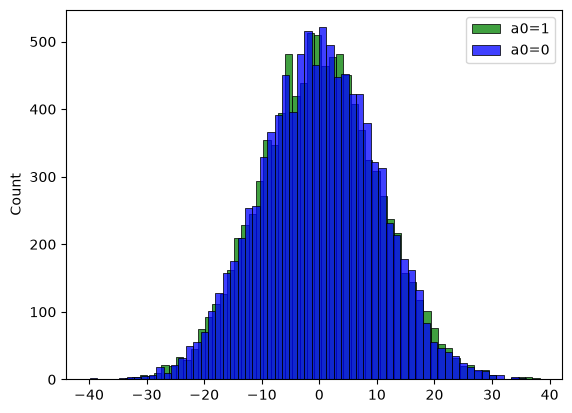

In [18]:
A_1,M_1,X_1,Y_1=DGP_null_U(10000,seed=0,gt=True,a0=1,u_scale=10)
A_0,M_0,X_0,Y_0=DGP_null_U(10000,seed=1,gt=True,a0=0,u_scale=10)
print(A_1.shape)
print(M_1.shape)
print(X_1.shape)
print(Y_1.shape)
sns.histplot(Y_1.ravel(),color="green",label="a0=1")
sns.histplot(Y_0.ravel(),color="blue",label="a0=0")
plt.legend()
plt.show()

In [6]:
def analyse_KTE(T,null=False,ns=None):
    T_p_vals=jnp.ones(T.shape)-norm.cdf(T,loc=0,scale=1)
    rejection=T_p_vals<=0.05
    def statistic(*args,axis=-1):
        sample=jnp.array(args)
        rejection=sample<=0.05
        return jnp.mean(rejection,axis=axis)

    res=bootstrap(T_p_vals,statistic,axis=-1,vectorized=False,method='basic',confidence_level=0.95,n_resamples=999)
    top_errors=res.confidence_interval.high-jnp.mean(rejection,axis=1)
    bottom_errors=jnp.mean(rejection,axis=1)-res.confidence_interval.low
    errs=jnp.vstack((bottom_errors,top_errors))
    if ns is None:
        ns=200*jnp.arange(1,6)
    plt.errorbar(ns,jnp.mean(rejection,axis=1),yerr=errs,fmt='o',capsize=5,label='positive test rate')
    if null:
        plt.plot(ns,0.05*jnp.ones(ns.shape),'--',color='black',label='cutoff')
    plt.xlabel('n')
    plt.ylabel('positive test rate')
    plt.ylim(0,1)
    plt.yticks(jnp.arange(21)/20)
    plt.legend()
    plt.show()

0
50
100
150
0
50
100
150
0
50
100
150
0
50
100
150
0
50
100
150


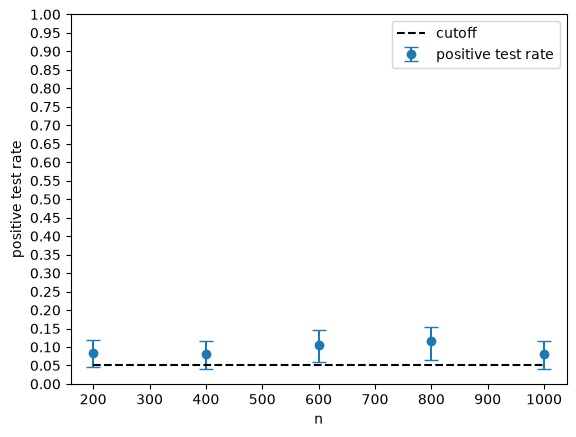

In [5]:
dim=3
n=500

outer_list=[]
n_list=[200,400,600,800,1000]

A,M,X,Y = DGP_null(2000,seed=0,dim=dim)

params=learn_hyperparams(A,M,X,Y,subsample=False)

for i in range(len(n_list)):
    n=n_list[i]
    inner_list=[]
    for j in range(200):
        if j%50==0:
            print(j)
        A,M,X,Y = DGP_null(2*n,seed=j,dim=dim)
        A_1=A[:n,:]
        A_2=A[n:,:]
        M_1=M[:n,:]
        M_2=M[n:,:]
        X_1=X[:n,:]
        X_2=X[n:,:]
        Y_1=Y[:n,:]
        Y_2=Y[n:,:]

        T=KTE(A_1,M_1,X_1,Y_1,A_2,M_2,X_2,Y_2,x_method='reggbm',mx_method='reggbm',params=params)
        inner_list.append(T)
    outer_list.append(inner_list)


T_vals=jnp.array(outer_list)
with open('null_success_rate.npy', 'wb') as f:
    jnp.save(f, T_vals)

analyse_KTE(T_vals,null=True)

0
50
100
150
0
50
100
150
0
50
100
150
0
50
100
150
0
50
100
150


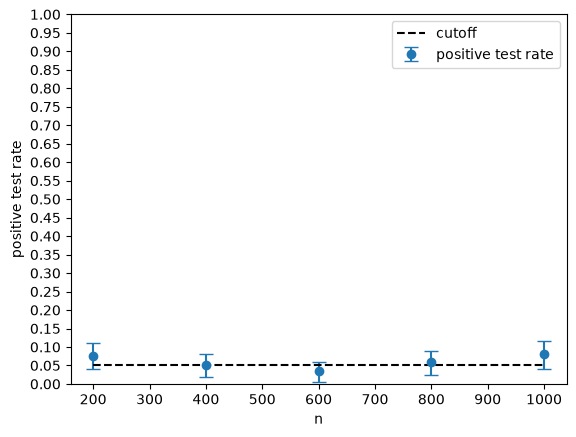

In [7]:
dim=3
n=500

outer_list=[]
n_list=[200,400,600,800,1000]

A,M,X,Y = DGP_binary(2000,seed=0,dim=dim,null=True)

params=learn_hyperparams(A,M,X,Y,subsample=False)

for i in range(len(n_list)):
    n=n_list[i]
    inner_list=[]
    for j in range(200):
        if j%50==0:
            print(j)
        A,M,X,Y = DGP_binary(2*n,seed=j,dim=dim,null=True)
        A_1=A[:n,:]
        A_2=A[n:,:]
        M_1=M[:n,:]
        M_2=M[n:,:]
        X_1=X[:n,:]
        X_2=X[n:,:]
        Y_1=Y[:n,:]
        Y_2=Y[n:,:]

        T=KTE(A_1,M_1,X_1,Y_1,A_2,M_2,X_2,Y_2,x_method='logistic',mx_method='logistic',params=params)
        inner_list.append(T)
    outer_list.append(inner_list)


T_vals=jnp.array(outer_list)

analyse_KTE(T_vals,null=True)

0
50
100
150
0
50
100
150
0
50
100
150
0
50
100
150
0
50
100
150


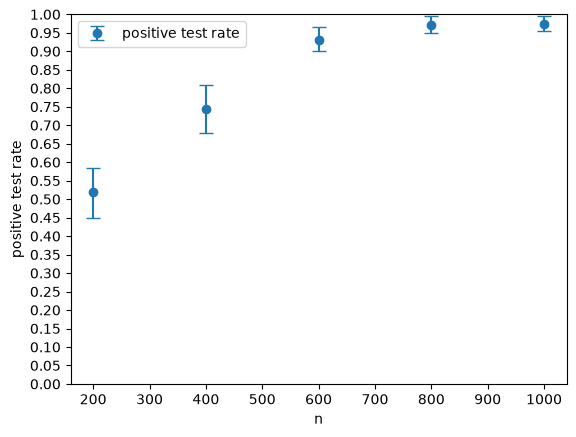

In [6]:
dim=3
n=500

outer_list=[]
n_list=[200,400,600,800,1000]

A,M,X,Y = DGP_univariate(2000,seed=0,dim=dim)

params=learn_hyperparams(A,M,X,Y,subsample=False)

for i in range(len(n_list)):
    n=n_list[i]
    inner_list=[]
    for j in range(200):
        if j%50==0:
            print(j)
        A,M,X,Y = DGP_univariate(2*n,seed=j,dim=dim)
        A_1=A[:n,:]
        A_2=A[n:,:]
        M_1=M[:n,:]
        M_2=M[n:,:]
        X_1=X[:n,:]
        X_2=X[n:,:]
        Y_1=Y[:n,:]
        Y_2=Y[n:,:]

        T=KTE(A_1,M_1,X_1,Y_1,A_2,M_2,X_2,Y_2,x_method='reggbm',mx_method='reggbm',params=params)
        inner_list.append(T)
    outer_list.append(inner_list)


T_vals=jnp.array(outer_list)
with open('uni_success_rate.npy', 'wb') as f:
    jnp.save(f, T_vals)

analyse_KTE(T_vals)

0
50
100
150
0
50
100
150
0
50
100
150
0
50
100
150
0
50
100
150


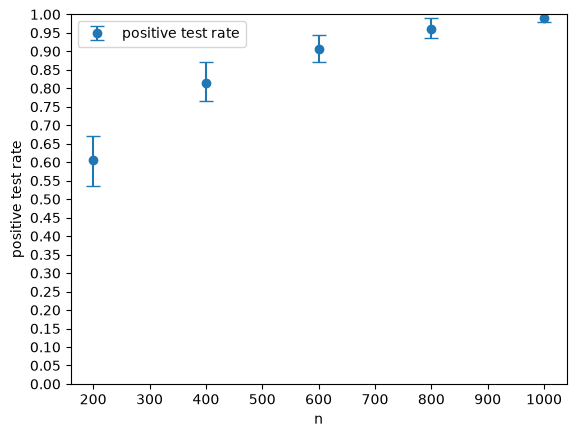

In [7]:
dim=3
n=500

outer_list=[]
n_list=[200,400,600,800,1000]

A,M,X,Y = DGP_multimodal(2000,seed=0,dim=dim)

params=learn_hyperparams(A,M,X,Y,subsample=False)

for i in range(len(n_list)):
    n=n_list[i]
    inner_list=[]
    for j in range(200):
        if j%50==0:
            print(j)
        A,M,X,Y = DGP_multimodal(2*n,seed=j,dim=dim)
        A_1=A[:n,:]
        A_2=A[n:,:]
        M_1=M[:n,:]
        M_2=M[n:,:]
        X_1=X[:n,:]
        X_2=X[n:,:]
        Y_1=Y[:n,:]
        Y_2=Y[n:,:]

        T=KTE(A_1,M_1,X_1,Y_1,A_2,M_2,X_2,Y_2,x_method='reggbm',mx_method='reggbm',params=params)
        inner_list.append(T)
    outer_list.append(inner_list)


T_vals=jnp.array(outer_list)
with open('multi_success_rate.npy', 'wb') as f:
    jnp.save(f, T_vals)

analyse_KTE(T_vals)

0
10
20
30
40
50
60
70
80
90
100
110
120
130
140
150
160
170
180
190
200
210
220
230
240
250
260
270
280
290
300
310
320
330
340
350
360
370
380
390
400
410
420
430
440
450
460
470
480
490


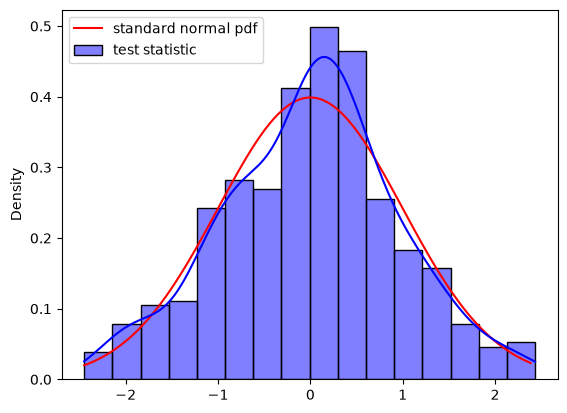

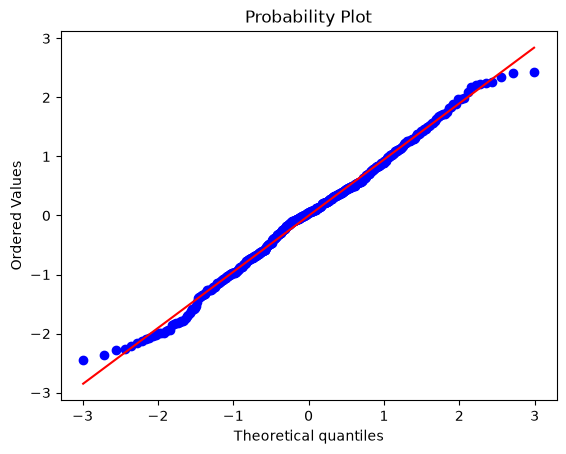

In [13]:
dim=3
n=2000

KTE_list_H_0=[]

A,M,X,Y = DGP_binary(2000,seed=0,dim=dim,null=True)

params=learn_hyperparams(A,M,X,Y,subsample=False)

for j in range(500):
    if j%10==0:
        print(j)
    A,M,X,Y = DGP_binary(2*n,seed=j,dim=dim,null=True)
    A_1=A[:n,:]
    A_2=A[n:,:]
    M_1=M[:n,:]
    M_2=M[n:,:]
    X_1=X[:n,:]
    X_2=X[n:,:]
    Y_1=Y[:n,:]
    Y_2=Y[n:,:]

    T=KTE(A_1,M_1,X_1,Y_1,A_2,M_2,X_2,Y_2,x_method='logistic',mx_method='logistic',params=params)
    KTE_list_H_0.append(T)


H_0=jnp.array(KTE_list_H_0)
dom=(jnp.max(H_0)-jnp.min(H_0))/100*jnp.arange(100)+jnp.min(H_0)
normal_pdf=norm.pdf(dom,loc=0,scale=1)
fig,ax=plt.subplots()
ax.plot(dom,normal_pdf,color='r',label='standard normal pdf')
sns.histplot(H_0,ax=ax,kde=True,stat='density',color='b',label='test statistic')
plt.legend()
plt.show()
plt.close()

res=probplot(H_0, plot=plt)
plt.show()
plt.close()

0
50
100
150
0
50
100
150
0
50
100
150
0
50
100
150
0
50
100
150
0
50
100
150


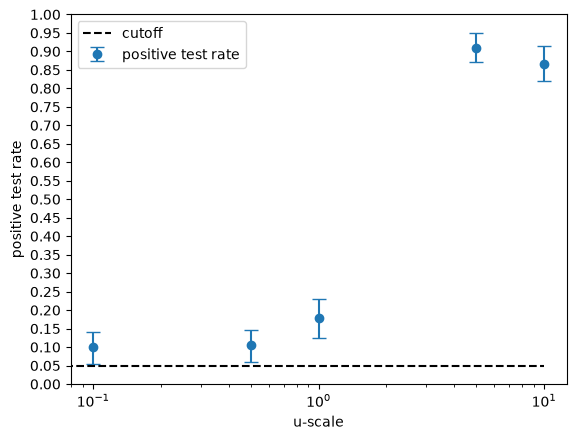

In [16]:
dim=1
n=1000

outer_list=[]
u_list=[0,0.1,0.5,1,5,10]

A,M,X,Y = DGP_null_U(2000,seed=0,dim=dim)

params=learn_hyperparams(A,M,X,Y,subsample=False)

for i in range(len(u_list)):
    u=u_list[i]
    inner_list=[]
    for j in range(200):
        if j%50==0:
            print(j)
        A,M,X,Y = DGP_null_U(2*n,seed=j,dim=dim, u_scale=u)
        A_1=A[:n,:]
        A_2=A[n:,:]
        M_1=M[:n,:]
        M_2=M[n:,:]
        X_1=X[:n,:]
        X_2=X[n:,:]
        Y_1=Y[:n,:]
        Y_2=Y[n:,:]

        T=KTE(A_1,M_1,X_1,Y_1,A_2,M_2,X_2,Y_2,x_method='reggbm',mx_method='reggbm',params=params)
        inner_list.append(T)
    outer_list.append(inner_list)


T_vals=jnp.array(outer_list)
with open('confounded_success_rate.npy', 'wb') as f:
    jnp.save(f, T_vals)

us=jnp.array(u_list)

T_p_vals=jnp.ones(T_vals.shape)-norm.cdf(T_vals,loc=0,scale=1)
rejection=T_p_vals<=0.05
def statistic(*args,axis=-1):
    sample=jnp.array(args)
    rejection=sample<=0.05
    return jnp.mean(rejection,axis=axis)

res=bootstrap(T_p_vals,statistic,axis=-1,vectorized=False,method='basic',confidence_level=0.95,n_resamples=999)
top_errors=res.confidence_interval.high-jnp.mean(rejection,axis=1)
bottom_errors=jnp.mean(rejection,axis=1)-res.confidence_interval.low
errs=jnp.vstack((bottom_errors,top_errors))
plt.errorbar(u_list,jnp.mean(rejection,axis=1),yerr=errs,fmt='o',capsize=5,label='positive test rate')
plt.plot(us,0.05*jnp.ones(us.shape),'--',color='black',label='cutoff')
plt.xlabel('u-scale')
plt.xscale('log')
plt.ylabel('positive test rate')
plt.ylim(0,1)
plt.yticks(jnp.arange(21)/20)
plt.legend()
plt.show()

0
25
0
25
0
25
0
25
0
25
0
25


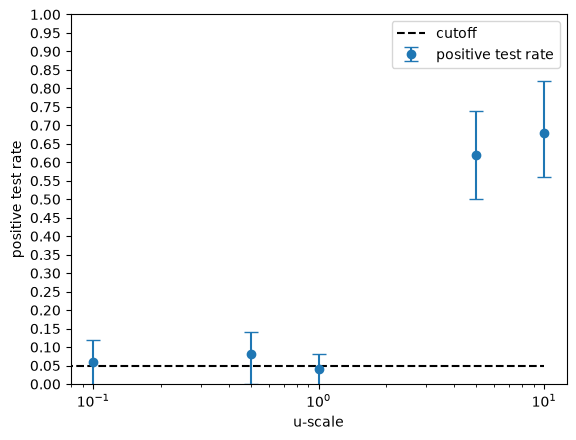

In [14]:
dim=1
n=1000

outer_list=[]
u_list=[0,0.1,0.5,1,5,10]

A,M,X,Y = DGP_null_U(2000,seed=0,dim=dim)

params=learn_hyperparams(A,M,X,Y,subsample=False)

for i in range(len(u_list)):
    u=u_list[i]
    inner_list=[]
    for j in range(50):
        if j%25==0:
            print(j)
        A,M,X,Y = DGP_null_U(2*n,seed=j,dim=dim, u_scale=u)
        A_1=A[:n,:]
        A_2=A[n:,:]
        M_1=M[:n,:]
        M_2=M[n:,:]
        X_1=X[:n,:]
        X_2=X[n:,:]
        Y_1=Y[:n,:]
        Y_2=Y[n:,:]

        T=KTE(A_1,M_1,X_1,Y_1,A_2,M_2,X_2,Y_2,x_method='forest',mx_method='forest',params=params)
        inner_list.append(T)
    outer_list.append(inner_list)


T_vals=jnp.array(outer_list)
with open('confounded_success_rate_forest.npy', 'wb') as f:
    jnp.save(f, T_vals)

us=jnp.array(u_list)

T_p_vals=jnp.ones(T_vals.shape)-norm.cdf(T_vals,loc=0,scale=1)
rejection=T_p_vals<=0.05
def statistic(*args,axis=-1):
    sample=jnp.array(args)
    rejection=sample<=0.05
    return jnp.mean(rejection,axis=axis)

res=bootstrap(T_p_vals,statistic,axis=-1,vectorized=False,method='basic',confidence_level=0.95,n_resamples=999)
top_errors=res.confidence_interval.high-jnp.mean(rejection,axis=1)
bottom_errors=jnp.mean(rejection,axis=1)-res.confidence_interval.low
errs=jnp.vstack((bottom_errors,top_errors))
plt.errorbar(u_list,jnp.mean(rejection,axis=1),yerr=errs,fmt='o',capsize=5,label='positive test rate')
plt.plot(us,0.05*jnp.ones(us.shape),'--',color='black',label='cutoff')
plt.xlabel('u-scale')
plt.xscale('log')
plt.ylabel('positive test rate')
plt.ylim(0,1)
plt.yticks(jnp.arange(21)/20)
plt.legend()
plt.show()